# Plates that can be made

Checks the section "A plate that can be made" of [`docs/networks/polarizer-classifier.md`](../../docs/networks/polarizer-classifier.md):
predictions Q1 to Q5, written on 19 Nov 2026 before any run with rounding, noise or shifts. A made plate has a few angle levels,
some error in every angle, and sits a little off. This notebook builds on [`polarizer_classifier.ipynb`](polarizer_classifier.ipynb)
(same model, same recipe, same 4 epochs, seeds 0, 1, 2, the full 10000 test digits).

**Live and loaded.** The training numbers are **measured** (a training run, then an evaluation on 10000 test digits) and are
**loaded** from `results/fabrication.json`, which is written by

    /c/ProgramData/miniconda3/python.exe experiments/optics/run_fabrication.py

(about an hour on the GPU). Live here, on a CPU, in about a minute: the half-turn check, and a rebuild of the exported
4-level plates from their PNG files, evaluated on the first 2000 test digits and set next to the stored accuracy.

**What was fixed before the run** (also at the top of `run_fabrication.py`):
- Determinism: the retrained free plates are compared with the round-1 accuracy in `sweep.json`; a difference above **0.005** is a problem.
- "The free plate" in Q1 to Q5 is the free plate **retrained in this run** with the same seed (its accuracy is within the determinism limit of round 1 if the check below holds).
- Shifts are along `+x` (columns), of plates 2 and 3 of the stack (plate 1 stays in the plane of the digit) or of the one plate of `linear3`; the plate and its aperture move together and the edge is filled with zeros, nothing wraps.
- Levels: `linear3` to {45, 135} or {0, 45, 90, 135} degrees; the stack to 4, 8, 16 evenly spaced levels from 0 over 180 degrees. Angles are taken modulo 180 degrees; the nearest level is measured round the half-turn.
- Angle error is Gaussian, added to every angle after the rounding (for rounded plates), 5 draws per setting; the mean of the 5 accuracies is used.
- Each prediction is judged per seed and **fails if it fails on two of three seeds**. A verdict prints `held` or `failed`, computed from the numbers.

In [1]:
import json, math, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from PIL import Image

OPTICS_DIR = Path.cwd()
REPO = OPTICS_DIR.parent.parent
sys.path.insert(0, str(OPTICS_DIR))
sys.path.insert(0, str(REPO / "experiments" / "part1"))
import optics
from common import use_style, BEFORE, MODEL

torch.set_default_dtype(torch.float32)     # common.py sets float64; every tensor below says its dtype anyway
use_style()
torch.manual_seed(0)
START = time.time()
RESULTS = OPTICS_DIR / "results"
FIGURES = REPO / "graphs"
FIGURES.mkdir(exist_ok=True)
fabrication = json.loads((RESULTS / "fabrication.json").read_text())
sweep = json.loads((RESULTS / "sweep.json").read_text())
SEEDS = fabrication["settings"]["seeds"]
RUNS = {seed: fabrication["runs"][str(seed)] for seed in SEEDS}
DESIGN_GAP = fabrication["settings"]["design_gap"]
print("settings:", {key: value for key, value in fabrication["settings"].items() if key != "design_gap"})
print(f"torch {fabrication['torch_version']} on {fabrication.get('gpu', fabrication['device'])}; run wall time {fabrication['wall_seconds'] / 60:.1f} minutes")

settings: {'epochs': 4, 'recipe': {'learning_rate': 0.1, 'temperature': 100.0, 'light_weight': 1.0}, 'seeds': [0, 1, 2], 'determinism_limit': 0.005, 'noise_degrees': [2, 5, 10], 'noise_draws': 5, 'shifts': [1, 2, 4], 'shift_train_range': 2, 'shift_direction': '+x (columns); plates 2 and 3 of the stack, the one plate of linear3', 'levels_linear_round': {'2level_45_135': [45.0, 135.0], '4level': [0.0, 45.0, 90.0, 135.0]}, 'levels_stack_round': {'4level': 4, '8level': 8, '16level': 16}}
torch 2.6.0+cu124 on NVIDIA GeForce RTX 4070 Laptop GPU; run wall time 65.9 minutes


## A half turn of the axis changes nothing

A plate axis at `theta` and at `theta + 180 degrees` is the same plate (`u -> -u` leaves `u (u . E)` as it was), so the angles
are taken modulo 180 degrees before rounding. The run script added a half turn to every angle of an untrained three-plate stack
and compared the brightness on the screen for 20 test digits; the same is repeated here live. This tests the code against the
algebra; both could be wrong together only if the model were not the one in the note. The largest brightness on that screen
is also printed, to put the difference in scale.

In [2]:
test_images, test_labels = optics.load_mnist(root=str(OPTICS_DIR / "data"), device="cpu")["test"]
probe = optics.Device("pol_stack3", seed=0, design_gap=DESIGN_GAP)
with torch.no_grad():
    before, _ = probe.get_screen(test_images[:8])
    for table in probe.plates:
        table.add_(math.pi)
    after, _ = probe.get_screen(test_images[:8])
live_difference = float((before - after).abs().max())
print(f"live: largest brightness difference after adding 180 degrees to every angle {live_difference:.2e} (largest brightness {float(before.max()):.4f})")
print(f"stored (20 digits, GPU): {fabrication['half_turn_check']['max_difference']:.2e} (largest brightness {fabrication['half_turn_check']['max_brightness']:.4f})")
assert live_difference < 1e-6 * float(before.max()) * 100, "half turn changed the output"
print("[PASS] adding 180 degrees to every angle changes the screen by less than 1e-4 of its largest brightness")

live: largest brightness difference after adding 180 degrees to every angle 6.52e-09 (largest brightness 0.0205)
stored (20 digits, GPU): 6.52e-09 (largest brightness 0.0205)
[PASS] adding 180 degrees to every angle changes the screen by less than 1e-4 of its largest brightness


## Determinism of the retraining (a check that can fail)

The free `linear3` and `pol_stack3` were trained again with the same code, recipe and seeds as in round 1. If the training were
not reproducible, the later comparisons with "the free plate" would compare different plates. **A difference in test accuracy above
0.005 from the round-1 number is called a problem** (fixed before the run).

In [3]:
rows = []
for kind in ("linear3", "pol_stack3"):
    for seed in SEEDS:
        entry = RUNS[seed][f"free_{kind}"]
        rows.append(dict(device=kind, seed=seed, round2=entry["accuracy"], round1=entry["round1_accuracy"], difference=entry["difference"]))
determinism = pd.DataFrame(rows)
print(determinism.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
LIMIT = fabrication["settings"]["determinism_limit"]
worst = float(determinism["difference"].abs().max())
print(f"[{'PASS' if worst <= LIMIT else 'FAIL'}] retraining reproduces round 1: largest |difference| {worst:.4f} vs limit {LIMIT}")

    device  seed  round2  round1  difference
   linear3     0  0.8782  0.8782      0.0000
   linear3     1  0.8772  0.8772      0.0000
   linear3     2  0.8805  0.8805      0.0000
pol_stack3     0  0.9739  0.9739      0.0000
pol_stack3     1  0.9761  0.9761      0.0000
pol_stack3     2  0.9752  0.9752      0.0000
[PASS] retraining reproduces round 1: largest |difference| 0.0000 vs limit 0.005


## The measured tables (loaded from `fabrication.json`)

Test accuracy on the 10000 test digits; one column per seed and the mean.

In [4]:
def get_table(entries):
    """entries: name -> function(seed) -> accuracy"""
    table = pd.DataFrame({name: [function(seed) for seed in SEEDS] for name, function in entries.items()}, index=[f"seed {seed}" for seed in SEEDS]).T
    table["mean"] = table.mean(axis=1)
    return table


def show(title, entries):
    print(f"\n{title}")
    print(get_table(entries).to_string(float_format=lambda value: f"{value:.4f}"))


free = lambda kind: (lambda seed: RUNS[seed][f"free_{kind}"]["accuracy"])
show("free plates (retrained)", {"free linear3": free("linear3"), "free pol_stack3": free("pol_stack3")})
show("2. rounded AFTER training, no retraining", {
    "linear3, 2 levels (45, 135)": lambda seed: RUNS[seed]["free_linear3"]["rounded_after_training"]["2level_45_135"],
    "linear3, 4 levels": lambda seed: RUNS[seed]["free_linear3"]["rounded_after_training"]["4level"],
    "pol_stack3, 4 levels": lambda seed: RUNS[seed]["free_pol_stack3"]["rounded_after_training"]["4level"],
    "pol_stack3, 8 levels": lambda seed: RUNS[seed]["free_pol_stack3"]["rounded_after_training"]["8level"],
    "pol_stack3, 16 levels": lambda seed: RUNS[seed]["free_pol_stack3"]["rounded_after_training"]["16level"]})
show("3. rounded IN the training (straight-through: rounded angle forward; the gradient of the loss at the rounded angle is passed to the unrounded angle), evaluated rounded", {
    "linear3, 2 levels (45, 135)": lambda seed: RUNS[seed]["ste2_linear3"]["accuracy"],
    "linear3, 4 levels": lambda seed: RUNS[seed]["ste4_linear3"]["accuracy"],
    "pol_stack3, 4 levels": lambda seed: RUNS[seed]["ste4_pol_stack3"]["accuracy"]})
noise_entries = {}
for std in fabrication["settings"]["noise_degrees"]:
    noise_entries[f"free linear3, error {std} deg"] = (lambda std: lambda seed: RUNS[seed]["free_linear3"]["angle_error"][str(std)]["mean"])(std)
    noise_entries[f"free pol_stack3, error {std} deg"] = (lambda std: lambda seed: RUNS[seed]["free_pol_stack3"]["angle_error"][str(std)]["mean"])(std)
    noise_entries[f"4-level-trained stack, error {std} deg"] = (lambda std: lambda seed: RUNS[seed]["ste4_pol_stack3"]["angle_error"][str(std)]["mean"])(std)
show(f"4. Gaussian angle error on every angle (mean accuracy of {fabrication['settings']['noise_draws']} draws)", noise_entries)
shift_entries = {}
for shift in fabrication["settings"]["shifts"]:
    shift_entries[f"free linear3, plate shifted {shift} px"] = (lambda shift: lambda seed: RUNS[seed]["free_linear3"]["shift"][str(shift)])(shift)
    shift_entries[f"free pol_stack3, plates 2 and 3 shifted {shift} px"] = (lambda shift: lambda seed: RUNS[seed]["free_pol_stack3"]["shift"][str(shift)])(shift)
show("5. shifts at test time, free plates (+x, zero fill)", shift_entries)
show("6. pol_stack3 trained with a random shift of every plate in [-2, 2] px (x and y) at every step; evaluated with plates 2 and 3 shifted",
     {f"shift-trained stack, shift {shift} px": (lambda shift: lambda seed: RUNS[seed]["shift_pol_stack3"]["shift"][str(shift)])(shift) for shift in (0, 1, 2, 4)})


free plates (retrained)
                 seed 0  seed 1  seed 2   mean
free linear3     0.8782  0.8772  0.8805 0.8786
free pol_stack3  0.9739  0.9761  0.9752 0.9751

2. rounded AFTER training, no retraining
                             seed 0  seed 1  seed 2   mean
linear3, 2 levels (45, 135)  0.7602  0.8021  0.8255 0.7959
linear3, 4 levels            0.8400  0.8550  0.8560 0.8503
pol_stack3, 4 levels         0.9580  0.9607  0.9384 0.9524
pol_stack3, 8 levels         0.9716  0.9730  0.9723 0.9723
pol_stack3, 16 levels        0.9734  0.9743  0.9740 0.9739

3. rounded IN the training (straight-through: rounded angle forward; the gradient of the loss at the rounded angle is passed to the unrounded angle), evaluated rounded
                             seed 0  seed 1  seed 2   mean
linear3, 2 levels (45, 135)  0.0892  0.1000  0.0892 0.0928
linear3, 4 levels            0.7123  0.7123  0.7119 0.7122
pol_stack3, 4 levels         0.9669  0.9660  0.9659 0.9663

4. Gaussian angle error on every

## Live check: rebuild the exported 4-level plates from their PNG files

`run_fabrication.py` exported the 4-level-trained plates of seed 0 as 8-bit PNG (pixel value = level index x 60). Here the
files are read back, the pixel value is turned into an angle (`value / 60 x 45 degrees`), a **free-angle** device is built from them
(no rounding switched on), and it is evaluated on the first 2000 test digits on this CPU. The stored accuracy on the same 2000
digits was computed on the GPU from the rounded training parameters. **Before looking, a difference above 0.002 (4 digits of 2000)
is called a problem**; a larger one would mean the export or its reading is wrong.

In [5]:
def rebuild_from_png(kind, plate_count):
    model = optics.Device(kind, seed=0, design_gap=DESIGN_GAP)
    with torch.no_grad():
        for index in range(plate_count):
            pixels = np.array(Image.open(RESULTS / f"plate_{kind}_4level_{index}.png"))
            assert pixels.dtype == np.uint8 and set(np.unique(pixels)) <= {0, 60, 120, 180}
            model.plates[index].copy_(torch.tensor(np.radians(pixels.astype(np.float64) / 60.0 * 45.0), dtype=torch.float32))
    return model


png_rows = []
for kind, plate_count, name in (("linear3", 1, "ste4_linear3"), ("pol_stack3", 3, "ste4_pol_stack3")):
    started = time.time()
    model = rebuild_from_png(kind, plate_count)
    live = optics.evaluate(model, test_images[:2000], test_labels[:2000])["accuracy"]
    stored = RUNS[0][name]["accuracy_first2000"]
    png_rows.append(dict(device=kind, live_cpu_from_png=live, stored_gpu=stored, difference=live - stored, full_test_stored=RUNS[0][name]["accuracy"], seconds=time.time() - started))
png_check = pd.DataFrame(png_rows)
print(png_check.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
for row in png_rows:
    ok = abs(row["difference"]) <= 0.002
    print(f"[{'PASS' if ok else 'FAIL'}] {row['device']}: PNG rebuild vs stored accuracy on 2000 digits, |difference| {abs(row['difference']):.4f} (limit 0.002)")

    device  live_cpu_from_png  stored_gpu  difference  full_test_stored  seconds
   linear3             0.6670      0.6670      0.0000            0.7123   3.0825
pol_stack3             0.9535      0.9535      0.0000            0.9669   6.3362
[PASS] linear3: PNG rebuild vs stored accuracy on 2000 digits, |difference| 0.0000 (limit 0.002)
[PASS] pol_stack3: PNG rebuild vs stored accuracy on 2000 digits, |difference| 0.0000 (limit 0.002)


## Verdicts on Q1 to Q5

Computed from the tables above by the rules of the note, per seed. A prediction **fails if it fails on two of three seeds**.

- **Q1** (two angles are enough between crossed polarizers): `linear3` trained with the angles rounded to 45 and 135 degrees is within 0.02 of the free plate: `free - ste2 <= 0.02`.
- **Q2** (rounding that plate after training): `linear3` rounded to 0, 45, 90, 135 with no retraining loses less than 0.05.
- **Q3** (the stack needs the rounding in the training): rounding the free three-plate stack to four levels after training loses more than 0.10, **and** the four-level stack trained with the rounding reaches at least 0.94.
- **Q4** (plates that sit off): the free stack loses more than 0.20 when plates 2 and 3 are each moved 2 pixels, **and** the shift-trained stack loses less than 0.05 at that shift, **and** is within 0.03 of the free stack when nothing is shifted.
- **Q5** (error in the angles): 5 degrees of Gaussian error on every angle costs the free stack less than 0.02 (mean of the 5 draws).

In [6]:
def judge(name, per_seed_lines, per_seed_ok):
    failures = sum(1 for ok in per_seed_ok if not ok)
    print(f"{name}: {'failed' if failures >= 2 else 'held'}   (fails on {failures} of {len(SEEDS)} seeds)")
    for seed, line, ok in zip(SEEDS, per_seed_lines, per_seed_ok):
        print(f"   seed {seed}: {'ok' if ok else 'FAILS'} | {line}")


# Q1
lines, oks = [], []
for seed in SEEDS:
    free_accuracy, rounded_accuracy = RUNS[seed]["free_linear3"]["accuracy"], RUNS[seed]["ste2_linear3"]["accuracy"]
    lines.append(f"free {free_accuracy:.4f}, trained at 45/135 deg {rounded_accuracy:.4f}, loss {free_accuracy - rounded_accuracy:+.4f} (needs <= 0.02)")
    oks.append(free_accuracy - rounded_accuracy <= 0.02)
judge("Q1", lines, oks)

# Q2
lines, oks = [], []
for seed in SEEDS:
    free_accuracy, rounded_accuracy = RUNS[seed]["free_linear3"]["accuracy"], RUNS[seed]["free_linear3"]["rounded_after_training"]["4level"]
    lines.append(f"free {free_accuracy:.4f}, rounded to 4 levels after training {rounded_accuracy:.4f}, loss {free_accuracy - rounded_accuracy:+.4f} (needs < 0.05)")
    oks.append(free_accuracy - rounded_accuracy < 0.05)
judge("Q2", lines, oks)

# Q3
lines, oks = [], []
for seed in SEEDS:
    free_accuracy, rounded_accuracy = RUNS[seed]["free_pol_stack3"]["accuracy"], RUNS[seed]["free_pol_stack3"]["rounded_after_training"]["4level"]
    trained_accuracy = RUNS[seed]["ste4_pol_stack3"]["accuracy"]
    lines.append(f"free {free_accuracy:.4f}, rounded after {rounded_accuracy:.4f} (loss {free_accuracy - rounded_accuracy:+.4f}, needs > 0.10); trained with rounding {trained_accuracy:.4f} (needs >= 0.94)")
    oks.append(free_accuracy - rounded_accuracy > 0.10 and trained_accuracy >= 0.94)
judge("Q3", lines, oks)

# Q4
lines, oks = [], []
for seed in SEEDS:
    free_zero = RUNS[seed]["free_pol_stack3"]["accuracy"]
    free_two = RUNS[seed]["free_pol_stack3"]["shift"]["2"]
    trained_zero, trained_two = RUNS[seed]["shift_pol_stack3"]["shift"]["0"], RUNS[seed]["shift_pol_stack3"]["shift"]["2"]
    parts = [free_zero - free_two > 0.20, trained_zero - trained_two < 0.05, abs(free_zero - trained_zero) <= 0.03]
    lines.append(f"free {free_zero:.4f} -> {free_two:.4f} at 2 px (loss {free_zero - free_two:+.4f}, needs > 0.20); shift-trained {trained_zero:.4f} -> {trained_two:.4f} "
                 f"(loss {trained_zero - trained_two:+.4f}, needs < 0.05); unshifted gap to free {abs(free_zero - trained_zero):.4f} (needs <= 0.03); parts {parts}")
    oks.append(all(parts))
judge("Q4", lines, oks)

# Q5
lines, oks = [], []
for seed in SEEDS:
    free_accuracy, noisy = RUNS[seed]["free_pol_stack3"]["accuracy"], RUNS[seed]["free_pol_stack3"]["angle_error"]["5"]
    lines.append(f"free {free_accuracy:.4f}, with 5 deg error {noisy['mean']:.4f} (draws {', '.join(f'{value:.4f}' for value in noisy['draws'])}), loss {free_accuracy - noisy['mean']:+.4f} (needs < 0.02)")
    oks.append(free_accuracy - noisy["mean"] < 0.02)
judge("Q5", lines, oks)
print(f"\nlive time so far {time.time() - START:.0f} s")

Q1: failed   (fails on 3 of 3 seeds)
   seed 0: FAILS | free 0.8782, trained at 45/135 deg 0.0892, loss +0.7890 (needs <= 0.02)
   seed 1: FAILS | free 0.8772, trained at 45/135 deg 0.1000, loss +0.7772 (needs <= 0.02)
   seed 2: FAILS | free 0.8805, trained at 45/135 deg 0.0892, loss +0.7913 (needs <= 0.02)
Q2: held   (fails on 0 of 3 seeds)
   seed 0: ok | free 0.8782, rounded to 4 levels after training 0.8400, loss +0.0382 (needs < 0.05)
   seed 1: ok | free 0.8772, rounded to 4 levels after training 0.8550, loss +0.0222 (needs < 0.05)
   seed 2: ok | free 0.8805, rounded to 4 levels after training 0.8560, loss +0.0245 (needs < 0.05)
Q3: failed   (fails on 3 of 3 seeds)
   seed 0: FAILS | free 0.9739, rounded after 0.9580 (loss +0.0159, needs > 0.10); trained with rounding 0.9669 (needs >= 0.94)
   seed 1: FAILS | free 0.9761, rounded after 0.9607 (loss +0.0154, needs > 0.10); trained with rounding 0.9660 (needs >= 0.94)
   seed 2: FAILS | free 0.9752, rounded after 0.9384 (loss +0.

## Figure

`graphs/optics_fabrication.png`, no title. **Alt text.** Left panel: test accuracy (vertical) against the number of angle levels
(horizontal, 2 to 16, log scale), for the one-plate crossed-linear device (`linear3`) and the three-plate stack. Crosses are
plates rounded after training, filled dots are plates trained with the rounding; one mark per seed and a line through the means.
Right panel: test accuracy against the sideways shift of plates 2 and 3 in pixels, for the free stack (grey) and the stack trained with random shifts (purple); one dot per seed, a line through the means.
Both panels are drawn from `fabrication.json`.

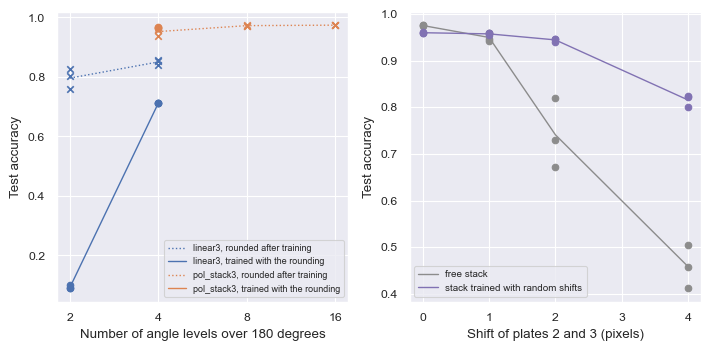

notebook live time 12 s


In [7]:
palette = sns.color_palette("deep")
colours = {"linear3": palette[0], "pol_stack3": palette[1]}
figure, (left, right) = plt.subplots(1, 2, figsize=(7.2, 3.6))
series = [
    ("linear3", "rounded after training", "x", {2: lambda seed: RUNS[seed]["free_linear3"]["rounded_after_training"]["2level_45_135"],
                                               4: lambda seed: RUNS[seed]["free_linear3"]["rounded_after_training"]["4level"]}),
    ("linear3", "trained with the rounding", "o", {2: lambda seed: RUNS[seed]["ste2_linear3"]["accuracy"], 4: lambda seed: RUNS[seed]["ste4_linear3"]["accuracy"]}),
    ("pol_stack3", "rounded after training", "x", {level: (lambda level: lambda seed: RUNS[seed]["free_pol_stack3"]["rounded_after_training"][f"{level}level"])(level) for level in (4, 8, 16)}),
    ("pol_stack3", "trained with the rounding", "o", {4: lambda seed: RUNS[seed]["ste4_pol_stack3"]["accuracy"]}),
]
for kind, how, marker, by_level in series:
    levels = sorted(by_level)
    means = []
    for level in levels:
        values = [by_level[level](seed) for seed in SEEDS]
        left.scatter([level] * len(values), values, marker=marker, color=colours[kind], s=22, zorder=3)
        means.append(np.mean(values))
    left.plot(levels, means, color=colours[kind], linestyle="-" if marker == "o" else ":", linewidth=1.0, label=f"{kind}, {how}")
left.set_xscale("log", base=2)
left.set_xticks([2, 4, 8, 16])
left.set_xticklabels([2, 4, 8, 16])
left.set_xlabel("Number of angle levels over 180 degrees")
left.set_ylabel("Test accuracy")
left.legend(fontsize=6.5, loc="lower right")

shifts = [0, 1, 2, 4]
free_by_shift = {shift: [RUNS[seed]["free_pol_stack3"]["accuracy"] if shift == 0 else RUNS[seed]["free_pol_stack3"]["shift"][str(shift)] for seed in SEEDS] for shift in shifts}
trained_by_shift = {shift: [RUNS[seed]["shift_pol_stack3"]["shift"][str(shift)] for seed in SEEDS] for shift in shifts}
for values_by_shift, colour, label in ((free_by_shift, BEFORE, "free stack"), (trained_by_shift, MODEL, "stack trained with random shifts")):
    for shift in shifts:
        right.scatter([shift] * len(SEEDS), values_by_shift[shift], color=colour, s=22, zorder=3)
    right.plot(shifts, [np.mean(values_by_shift[shift]) for shift in shifts], color=colour, linewidth=1.0, label=label)
right.set_xlabel("Shift of plates 2 and 3 (pixels)")
right.set_ylabel("Test accuracy")
right.legend(fontsize=7, loc="lower left")
figure.tight_layout()
figure.savefig(FIGURES / "optics_fabrication.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"notebook live time {time.time() - START:.0f} s")